# Customer Churn Prediction — Exploratory Data Analysis

## 1. Project Introduction

**What is customer churn?**
Customer churn refers to customers who stop using a company's product or service within a given
period. In a subscription business (like the telecom company in this dataset), a churned customer
is one who has cancelled their service.

**Why predict churn?**
Acquiring a new customer is typically far more expensive than retaining an existing one. If a
company can identify customers who are *likely* to churn before they actually leave, it can take
proactive action (discounts, better support, personalized offers) to retain them. This makes churn
prediction a high-value, widely-used business application of machine learning.

**Objective of this notebook**
This notebook performs **Exploratory Data Analysis (EDA) only**. The goals are to:
- Understand the structure and quality of the raw dataset
- Identify data quality issues (missing values, inconsistent types, duplicates)
- Understand the target variable (`Churn`) and its class balance
- Explore how individual features relate to churn, using only descriptive statistics and
  visualizations (no modeling, no inferential claims of causation)
- Produce clear, evidence-based recommendations for the preprocessing notebook that follows

No models are trained here. No data is transformed or saved here — this notebook only *reads* the
raw CSV and produces plots/summary statistics.


## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Plot styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Paths (relative to the notebooks/ folder, project-root based)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Telco-Customer-Churn.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data path:", RAW_DATA_PATH)
print("Figures will be saved to:", FIGURES_DIR)


Project root: /path/to/customer-churn-prediction
Raw data path: /path/to/customer-churn-prediction/data/raw/Telco-Customer-Churn.csv
Figures will be saved to: /path/to/customer-churn-prediction/reports/figures


## 3. Load Dataset

We load the raw CSV exactly as-is. This dataframe (`df`) is used **read-only** throughout this
notebook — we never overwrite the raw CSV file.

In [2]:
df = pd.read_csv(RAW_DATA_PATH)
print(f"Dataset loaded successfully with shape: {df.shape}")


Dataset loaded successfully with shape: (7043, 21)


In [3]:
print("First 5 rows:")
df.head()


First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Last 5 rows:")
df.tail()


Last 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
print(f"Shape (rows, columns): {df.shape}")


Shape (rows, columns): (7043, 21)


In [6]:
print("Column names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:>2}. {col}")


Column names:
 1. customerID
 2. gender
 3. SeniorCitizen
 4. Partner
 5. Dependents
 6. tenure
 7. PhoneService
 8. MultipleLines
 9. InternetService
10. OnlineSecurity
11. OnlineBackup
12. DeviceProtection
13. TechSupport
14. StreamingTV
15. StreamingMovies
16. Contract
17. PaperlessBilling
18. PaymentMethod
19. MonthlyCharges
20. TotalCharges
21. Churn


## 4. Dataset Overview

We inspect data types, general info, descriptive statistics, and cardinality of each column.
Note upfront: `SeniorCitizen` is encoded as 0/1 (integer) even though it is conceptually
categorical, and `TotalCharges` is currently read as **text (object)**, not numeric — this is a
data quality issue we investigate in Section 5.

In [7]:
df.dtypes


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [8]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
# Descriptive statistics for numerical columns
df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
# Descriptive statistics for all columns (including categorical), to see counts/unique/top/freq
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# Number of unique values per column
unique_counts = df.nunique().sort_values(ascending=False)
unique_counts


customerID          7043
TotalCharges        6531
MonthlyCharges      1585
tenure                73
PaymentMethod          4
StreamingMovies        3
TechSupport            3
OnlineBackup           3
StreamingTV            3
DeviceProtection       3
MultipleLines          3
InternetService        3
OnlineSecurity         3
Contract               3
Partner                2
SeniorCitizen          2
gender                 2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
dtype: int64

## 5. Data Quality Check

We check, in order: missing values (`NaN`), blank/whitespace strings, duplicate rows, duplicate
customer IDs, invalid numeric values, and inconsistent categorical labels.

**Important:** all checks below are read-only. We do not modify or save `df` in this notebook.

In [12]:
# 5.1 Missing values (NaN) per column
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df) * 100).round(2)
missing_summary = pd.DataFrame({"missing_count": missing_counts, "missing_pct": missing_pct})
missing_summary = missing_summary[missing_summary["missing_count"] > 0]

if missing_summary.empty:
    print("No NaN values found in any column.")
else:
    print(missing_summary)


No NaN values found in any column.


In [13]:
# 5.2 Blank / whitespace-only strings hiding in object columns
# (These are NOT caught by isnull() because they are literal " " strings, not NaN)
object_cols = df.select_dtypes(include=["object", "string"]).columns
blank_string_report = {}

for col in object_cols:
    blank_count = (df[col].astype(str).str.strip() == "").sum()
    if blank_count > 0:
        blank_string_report[col] = blank_count

if blank_string_report:
    print("Columns containing blank/whitespace-only strings:")
    for col, count in blank_string_report.items():
        print(f"  - {col}: {count} blank value(s)")
else:
    print("No blank/whitespace-only strings found.")


Columns containing blank/whitespace-only strings:
  - TotalCharges: 11 blank value(s)


In [14]:
# 5.3 A closer look at TotalCharges specifically, since it is stored as text
print("TotalCharges dtype:", df["TotalCharges"].dtype)
print()
blank_totalcharges = df[df["TotalCharges"].astype(str).str.strip() == ""]
print(f"Rows with blank TotalCharges: {len(blank_totalcharges)}")
blank_totalcharges[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]


TotalCharges dtype: str

Rows with blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [15]:
# 5.4 Duplicate rows (full-row duplicates)
duplicate_rows = df.duplicated().sum()
print(f"Fully duplicated rows: {duplicate_rows}")

# 5.5 Duplicate customer IDs (should be unique identifiers)
duplicate_ids = df["customerID"].duplicated().sum()
print(f"Duplicate customerID values: {duplicate_ids}")


Fully duplicated rows: 0
Duplicate customerID values: 0


In [16]:
# 5.6 Invalid numeric values: negative tenure/charges, or tenure/charges out of a sane range
print("tenure range:", df["tenure"].min(), "to", df["tenure"].max())
print("MonthlyCharges range:", df["MonthlyCharges"].min(), "to", df["MonthlyCharges"].max())

negative_tenure = (df["tenure"] < 0).sum()
negative_monthly = (df["MonthlyCharges"] < 0).sum()
print(f"Negative tenure values: {negative_tenure}")
print(f"Negative MonthlyCharges values: {negative_monthly}")


tenure range: 0 to 72
MonthlyCharges range: 18.25 to 118.75
Negative tenure values: 0
Negative MonthlyCharges values: 0


In [17]:
# 5.7 Inconsistent categorical values — print unique values for every categorical column
# to visually confirm there are no typos/inconsistent casing (e.g. 'Yes' vs 'yes')
categorical_cols = df.select_dtypes(include=["object", "string"]).columns.drop("customerID")

for col in categorical_cols:
    print(f"{col}: {sorted(df[col].unique())}")


gender: ['Female', 'Male']
Partner: ['No', 'Yes']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No', 'No phone service', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'No internet service', 'Yes']
OnlineBackup: ['No', 'No internet service', 'Yes']
DeviceProtection: ['No', 'No internet service', 'Yes']
TechSupport: ['No', 'No internet service', 'Yes']
StreamingTV: ['No', 'No internet service', 'Yes']
StreamingMovies: ['No', 'No internet service', 'Yes']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['No', 'Yes']
PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
TotalCharges: [' ', '100.2', '100.25', '100.35', '100.4', '100.8', '100.9', '1001.2', '1001.5', '1003.05', '1004.35', '1004.5', '1004.75', '1005.7', '1006.9', '1007.8', '1007.9', '1008.55', '1008.7', '1009.25', '101.1', '101.45', '101.65', '101.9', '1010', '1011.05', '1011.5', '1011.8', '1012.4

**Data quality summary so far:**
The checks above are executed on the real dataset above; read the printed output for the exact
counts before drawing conclusions. In particular, pay attention to whether `TotalCharges` contains
blank strings, and whether those blank rows share a common characteristic (e.g. `tenure == 0`).
This will directly inform how we handle `TotalCharges` in the next notebook.

## 6. Target Variable Analysis

We now examine the target column, `Churn`.

In [18]:
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True).mul(100).round(2)

churn_summary = pd.DataFrame({"count": churn_counts, "percentage": churn_pct})
print(churn_summary)


       count  percentage
Churn                   
No      5174       73.46
Yes     1869       26.54


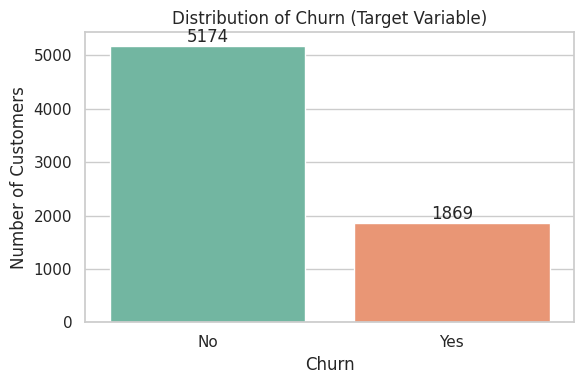

In [19]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Churn", hue="Churn", palette="Set2", legend=False, ax=ax)
ax.set_title("Distribution of Churn (Target Variable)")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "churn_distribution.png", dpi=150)
plt.show()


In [20]:
churn_rate = churn_pct["Yes"]
no_rate = churn_pct["No"]
print(f"Observed churn rate in this dataset: {churn_rate}% churned vs {no_rate}% retained.")
print("This is a class-imbalanced target: the 'No churn' class is the majority class.")


Observed churn rate in this dataset: 26.54% churned vs 73.46% retained.


This is a class-imbalanced target: the 'No churn' class is the majority class.


## 7. Numerical Feature Analysis

We analyze the three core numerical features: `tenure`, `MonthlyCharges`, and `TotalCharges`.

For this section, we create a **temporary, in-memory copy** (`df_num`) with `TotalCharges`
converted to numeric purely so we can compute statistics and plots. This copy is never saved to
disk and the original `df` / raw CSV are untouched.

In [21]:
df_num = df.copy()
df_num["TotalCharges"] = pd.to_numeric(df_num["TotalCharges"], errors="coerce")
print("Rows where TotalCharges became NaN after numeric conversion:", df_num["TotalCharges"].isnull().sum())


Rows where TotalCharges became NaN after numeric conversion: 11


In [22]:
df_num[["tenure", "MonthlyCharges", "TotalCharges"]].describe()


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


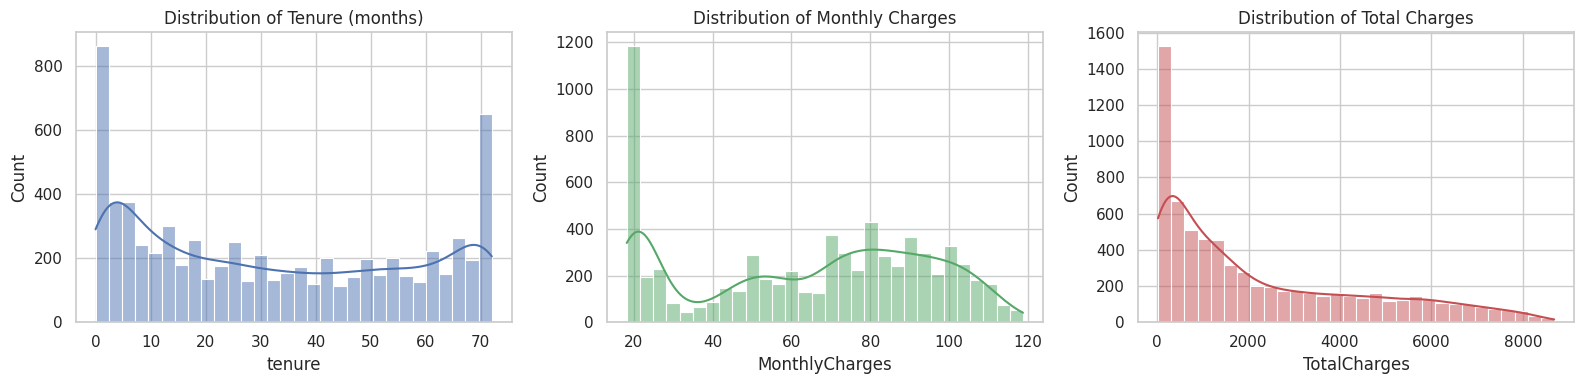

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df_num["tenure"], bins=30, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of Tenure (months)")

sns.histplot(df_num["MonthlyCharges"], bins=30, kde=True, ax=axes[1], color="#55A868")
axes[1].set_title("Distribution of Monthly Charges")

sns.histplot(df_num["TotalCharges"].dropna(), bins=30, kde=True, ax=axes[2], color="#C44E52")
axes[2].set_title("Distribution of Total Charges")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "tenure_distribution.png", dpi=150)
plt.savefig(FIGURES_DIR / "monthly_charges_distribution.png", dpi=150)
plt.show()


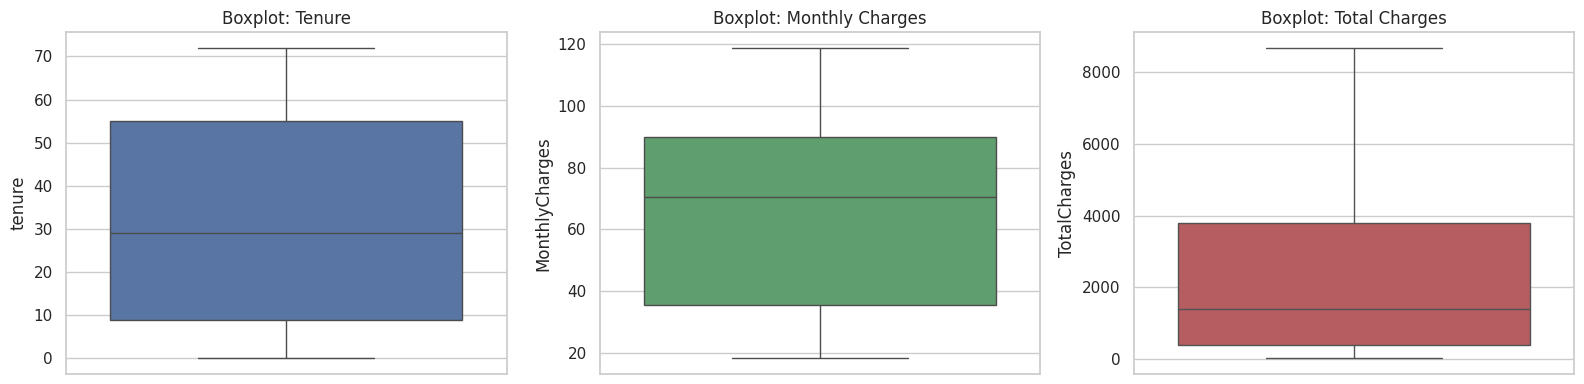

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(y=df_num["tenure"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Boxplot: Tenure")

sns.boxplot(y=df_num["MonthlyCharges"], ax=axes[1], color="#55A868")
axes[1].set_title("Boxplot: Monthly Charges")

sns.boxplot(y=df_num["TotalCharges"].dropna(), ax=axes[2], color="#C44E52")
axes[2].set_title("Boxplot: Total Charges")

plt.tight_layout()
plt.show()


## 8. Categorical Feature Analysis

We look at the distribution (counts) of key categorical/demographic variables, independent of
churn for now (churn relationships come in Section 9).

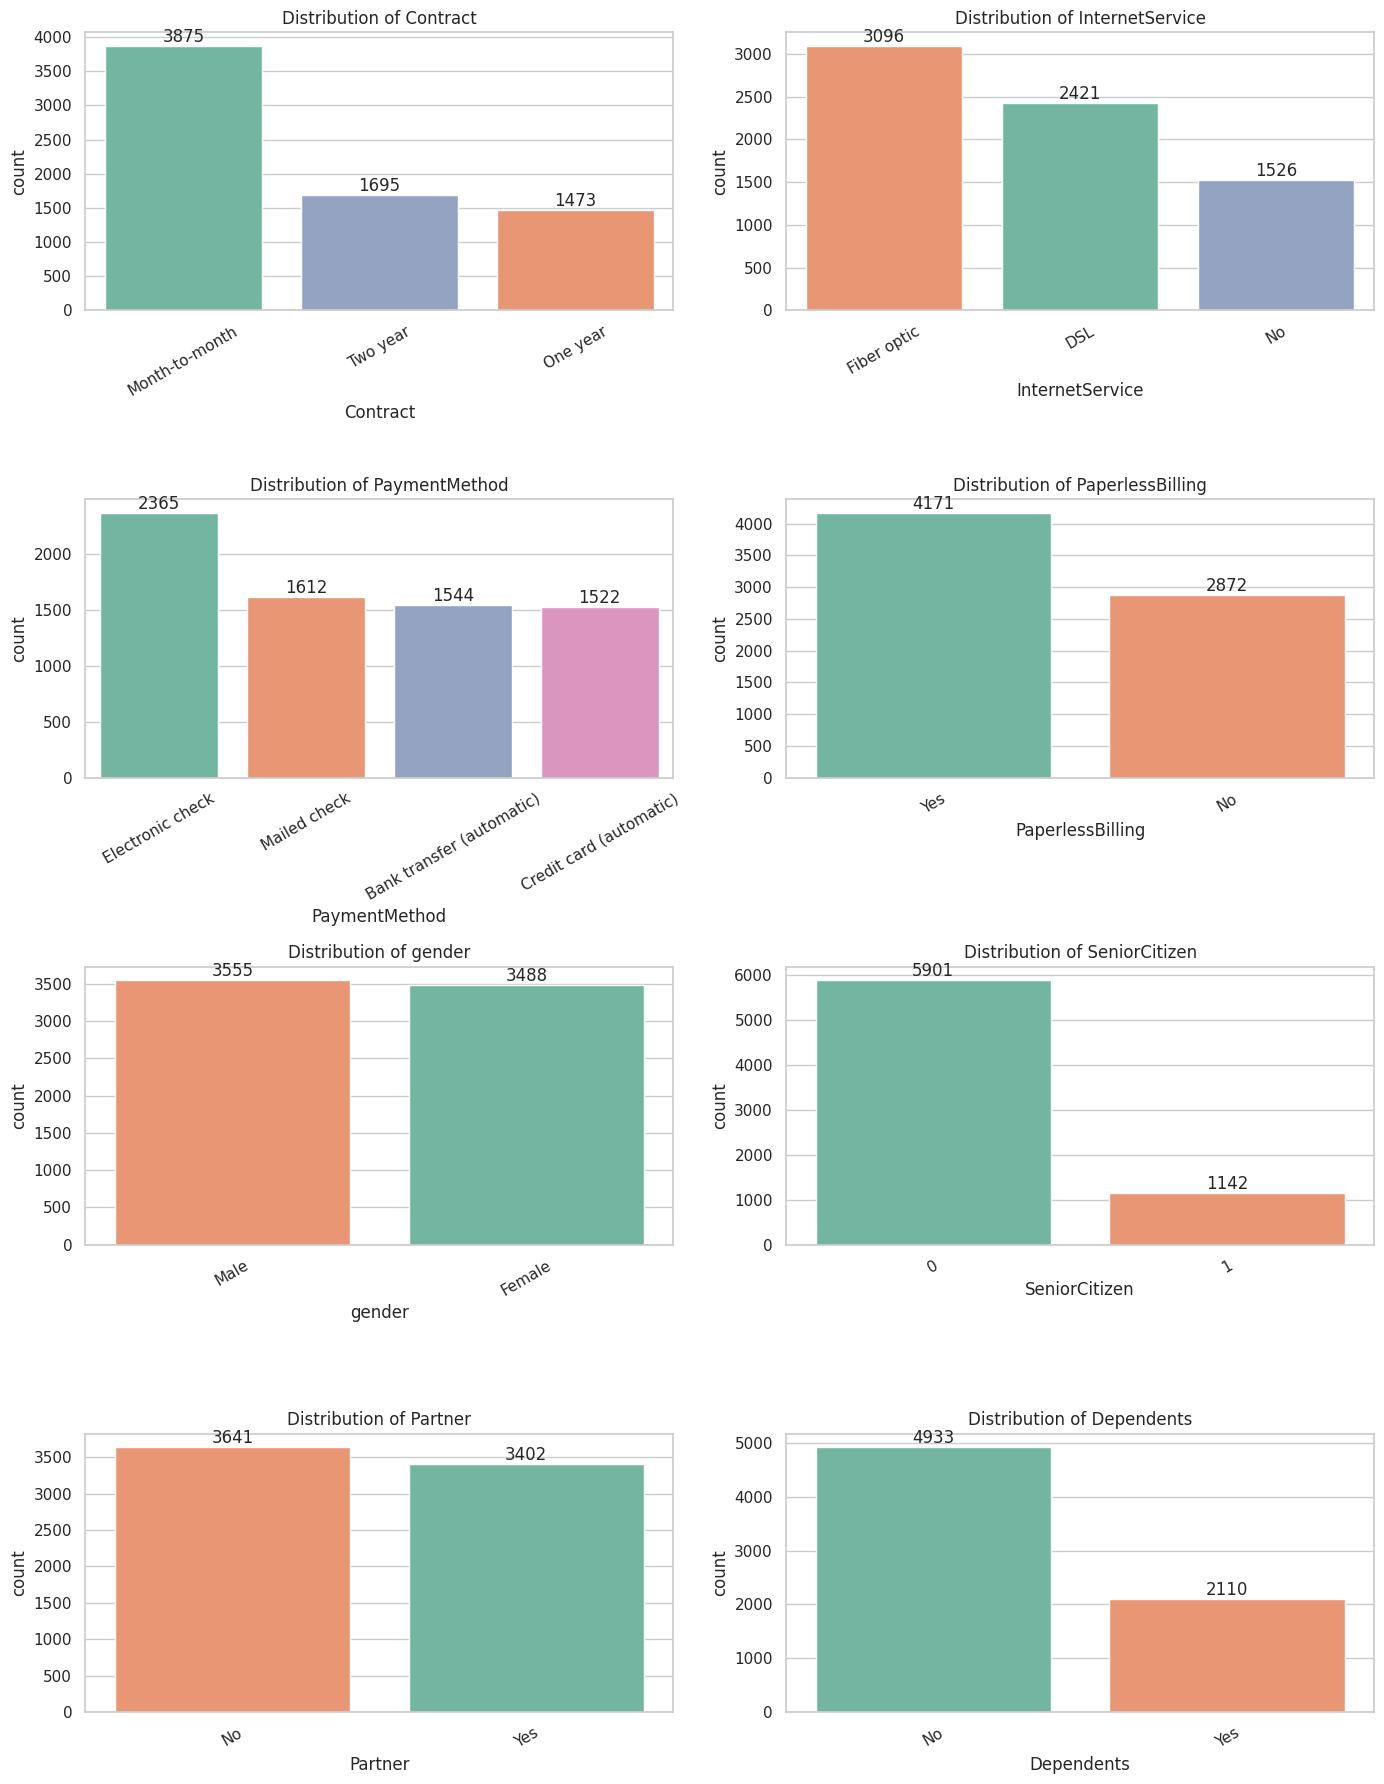

In [25]:
cat_features = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling",
                "gender", "SeniorCitizen", "Partner", "Dependents"]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, hue=col, order=order, palette="Set2", legend=False, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].tick_params(axis="x", rotation=30)
    for container in axes[i].containers:
        axes[i].bar_label(container)

plt.tight_layout()
plt.show()


In [26]:
for col in cat_features:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()


--- Contract ---
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- PaymentMethod ---
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

--- PaperlessBilling ---
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

--- gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- SeniorCitizen ---
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64



## 9. Churn Pattern Analysis

Here we calculate the **actual observed churn rate** within each category of several important
features. All percentages below are computed directly from the data — nothing is assumed.

**Important framing:** a higher churn rate observed in a group does **not** prove that the group's
characteristic *causes* churn. It only describes a pattern present in this historical dataset. We
phrase findings as "customers in this group have a higher observed churn rate in this dataset,"
not as causal statements.

In [27]:
def churn_rate_by_group(dataframe, column):
    """Return a DataFrame with churn rate (%) and customer count per category of `column`."""
    grouped = dataframe.groupby(column, observed=True)["Churn"].apply(
        lambda s: (s == "Yes").mean() * 100
    ).round(2)
    counts = dataframe.groupby(column, observed=True)["Churn"].count()
    result = pd.DataFrame({"churn_rate_pct": grouped, "customer_count": counts})
    return result.sort_values("churn_rate_pct", ascending=False)


In [28]:
print("Churn rate by Contract type:")
churn_by_contract = churn_rate_by_group(df, "Contract")
churn_by_contract


Churn rate by Contract type:


,churn_rate_pct,customer_count
Contract,,
Month-to-month,42.71,3875
One year,11.27,1473
Two year,2.83,1695


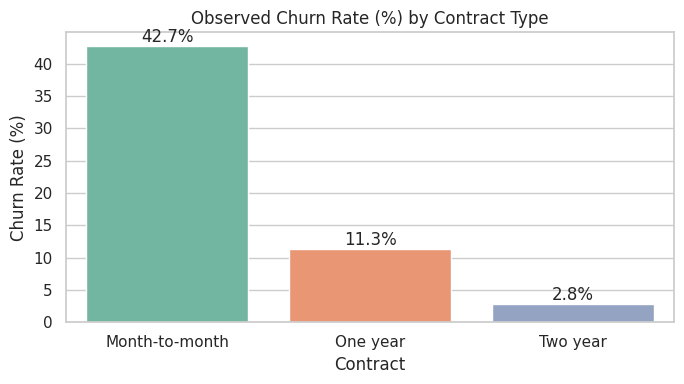

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=churn_by_contract.index, y=churn_by_contract["churn_rate_pct"],
            hue=churn_by_contract.index, palette="Set2", legend=False, ax=ax)
ax.set_title("Observed Churn Rate (%) by Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_xlabel("Contract")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "churn_by_contract.png", dpi=150)
plt.show()


In [30]:
print("Churn rate by Internet Service type:")
churn_by_internet = churn_rate_by_group(df, "InternetService")
churn_by_internet


Churn rate by Internet Service type:


,churn_rate_pct,customer_count
InternetService,,
Fiber optic,41.89,3096
DSL,18.96,2421
No,7.40,1526


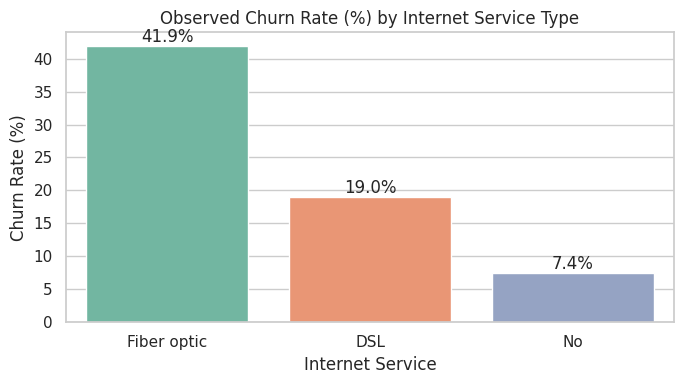

In [31]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=churn_by_internet.index, y=churn_by_internet["churn_rate_pct"],
            hue=churn_by_internet.index, palette="Set2", legend=False, ax=ax)
ax.set_title("Observed Churn Rate (%) by Internet Service Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_xlabel("Internet Service")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "churn_by_internet_service.png", dpi=150)
plt.show()


In [32]:
print("Churn rate by Payment Method:")
churn_by_payment = churn_rate_by_group(df, "PaymentMethod")
churn_by_payment


Churn rate by Payment Method:


,churn_rate_pct,customer_count
PaymentMethod,,
Electronic check,45.29,2365
Mailed check,19.11,1612
Bank transfer (automatic),16.71,1544
Credit card (automatic),15.24,1522


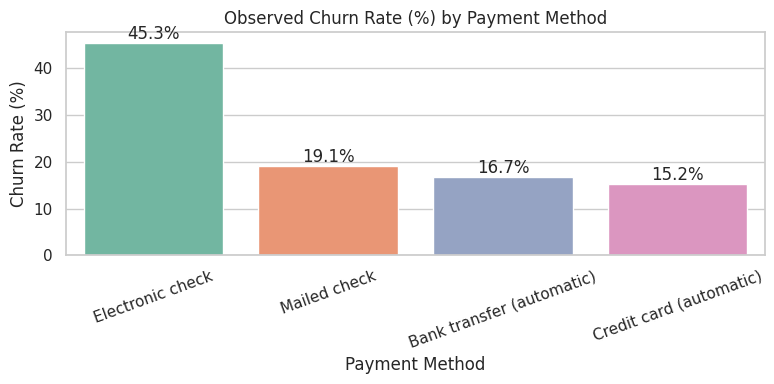

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=churn_by_payment.index, y=churn_by_payment["churn_rate_pct"],
            hue=churn_by_payment.index, palette="Set2", legend=False, ax=ax)
ax.set_title("Observed Churn Rate (%) by Payment Method")
ax.set_ylabel("Churn Rate (%)")
ax.set_xlabel("Payment Method")
ax.tick_params(axis="x", rotation=20)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "churn_by_payment_method.png", dpi=150)
plt.show()


In [34]:
print("Churn rate by PaperlessBilling:")
display(churn_rate_by_group(df, "PaperlessBilling"))

print("\nChurn rate by SeniorCitizen (0 = No, 1 = Yes):")
display(churn_rate_by_group(df, "SeniorCitizen"))

print("\nChurn rate by Partner:")
display(churn_rate_by_group(df, "Partner"))

print("\nChurn rate by Dependents:")
display(churn_rate_by_group(df, "Dependents"))


Churn rate by PaperlessBilling:


,churn_rate_pct,customer_count
PaperlessBilling,,
Yes,33.57,4171
No,16.33,2872



Churn rate by SeniorCitizen (0 = No, 1 = Yes):


,churn_rate_pct,customer_count
SeniorCitizen,,
1,41.68,1142
0,23.61,5901



Churn rate by Partner:


,churn_rate_pct,customer_count
Partner,,
No,32.96,3641
Yes,19.66,3402



Churn rate by Dependents:


,churn_rate_pct,customer_count
Dependents,,
No,31.28,4933
Yes,15.45,2110


In [35]:
# Churn rate by tenure group — we bin tenure (in months) into ranges for interpretability
df_tenure = df.copy()
bins = [0, 12, 24, 48, 60, 72]
labels = ["0-12", "13-24", "25-48", "49-60", "61-72"]
df_tenure["tenure_group"] = pd.cut(df_tenure["tenure"], bins=bins, labels=labels, include_lowest=True)

print("Churn rate by tenure group (months):")
churn_by_tenure_group = churn_rate_by_group(df_tenure, "tenure_group")
churn_by_tenure_group


Churn rate by tenure group (months):


,churn_rate_pct,customer_count
tenure_group,,
0-12,47.44,2186
13-24,28.71,1024
25-48,20.39,1594
49-60,14.42,832
61-72,6.61,1407


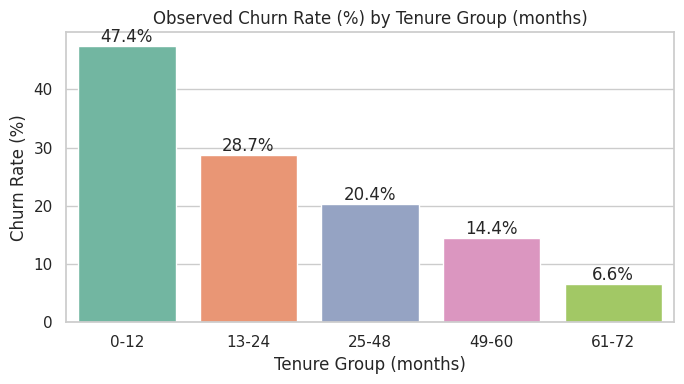

In [36]:
fig, ax = plt.subplots(figsize=(7, 4))
ordered = churn_by_tenure_group.reindex(labels)
sns.barplot(x=ordered.index, y=ordered["churn_rate_pct"], hue=ordered.index,
            palette="Set2", legend=False, ax=ax)
ax.set_title("Observed Churn Rate (%) by Tenure Group (months)")
ax.set_ylabel("Churn Rate (%)")
ax.set_xlabel("Tenure Group (months)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.tight_layout()
plt.show()


In [37]:
# Churn rate by MonthlyCharges group (quartile-based bins, for a roughly even group size)
df_charges = df.copy()
df_charges["monthly_charge_group"] = pd.qcut(df_charges["MonthlyCharges"], q=4,
                                              labels=["Low", "Medium-Low", "Medium-High", "High"])

print("Churn rate by MonthlyCharges group (quartiles):")
churn_by_charge_group = churn_rate_by_group(df_charges, "monthly_charge_group")
churn_by_charge_group


Churn rate by MonthlyCharges group (quartiles):


,churn_rate_pct,customer_count
monthly_charge_group,,
Medium-High,37.51,1757
High,32.88,1758
Medium-Low,24.58,1766
Low,11.24,1762


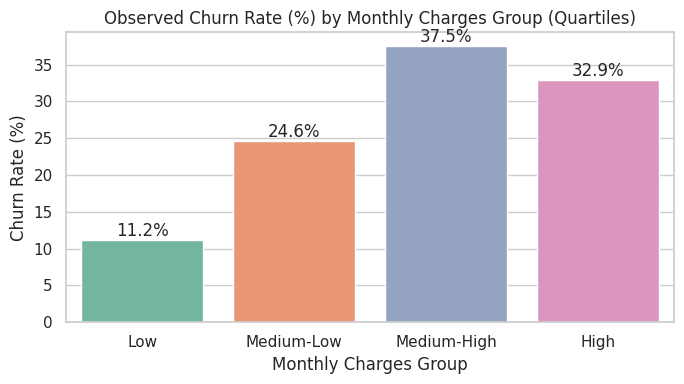

In [38]:
fig, ax = plt.subplots(figsize=(7, 4))
order = ["Low", "Medium-Low", "Medium-High", "High"]
ordered = churn_by_charge_group.reindex(order)
sns.barplot(x=ordered.index, y=ordered["churn_rate_pct"], hue=ordered.index,
            palette="Set2", legend=False, ax=ax)
ax.set_title("Observed Churn Rate (%) by Monthly Charges Group (Quartiles)")
ax.set_ylabel("Churn Rate (%)")
ax.set_xlabel("Monthly Charges Group")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.tight_layout()
plt.show()


## 10. Numerical Features vs Churn

We now look directly at how `tenure`, `MonthlyCharges`, and `TotalCharges` are *distributed*
between churned and retained customers, using boxplots and violin plots.

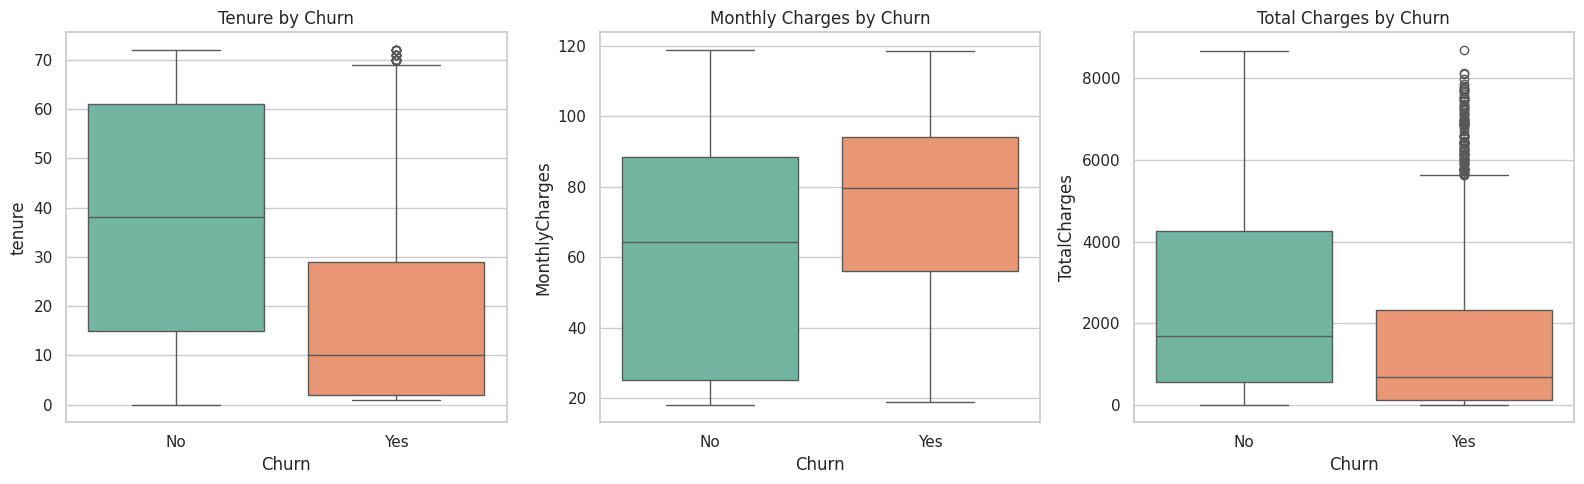

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df_num, x="Churn", y="tenure", hue="Churn", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Tenure by Churn")

sns.boxplot(data=df_num, x="Churn", y="MonthlyCharges", hue="Churn", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")

sns.boxplot(data=df_num, x="Churn", y="TotalCharges", hue="Churn", palette="Set2", legend=False, ax=axes[2])
axes[2].set_title("Total Charges by Churn")

plt.tight_layout()
plt.show()


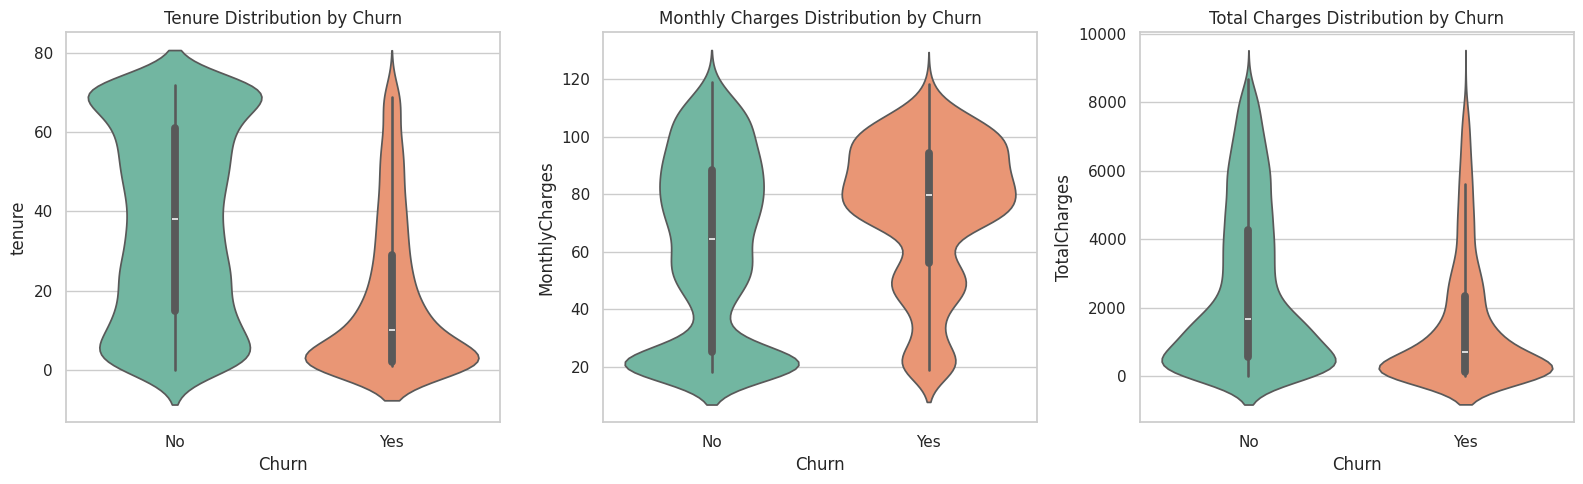

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.violinplot(data=df_num, x="Churn", y="tenure", hue="Churn", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Tenure Distribution by Churn")

sns.violinplot(data=df_num, x="Churn", y="MonthlyCharges", hue="Churn", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Monthly Charges Distribution by Churn")

sns.violinplot(data=df_num, x="Churn", y="TotalCharges", hue="Churn", palette="Set2", legend=False, ax=axes[2])
axes[2].set_title("Total Charges Distribution by Churn")

plt.tight_layout()
plt.show()


In [41]:
# Actual median values for a precise, non-visual comparison
comparison = df_num.groupby("Churn", observed=True)[["tenure", "MonthlyCharges", "TotalCharges"]].median()
print("Median values per Churn group:")
comparison


Median values per Churn group:


,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1683.60
Yes,10.0,79.650,703.55


## 11. Correlation Analysis

We compute pairwise correlation only among the numerical/numeric-encoded variables where a
correlation coefficient is meaningful: `tenure`, `MonthlyCharges`, `TotalCharges`, `SeniorCitizen`,
and a numeric-encoded version of `Churn` (0/1) purely for this analysis.

**What correlation can and cannot tell us:** the Pearson correlation coefficient measures the
strength and direction of a *linear* relationship between two numeric variables. It ranges from
-1 to 1. A value near 0 does not necessarily mean "no relationship" — it could be non-linear. Most
importantly, **correlation does not imply causation**: two variables can be correlated because one
causes the other, because a third variable influences both, or by coincidence. We use this analysis
only to spot linear associations worth investigating further, not to draw causal conclusions.

In [42]:
df_corr = df_num.copy()
df_corr["Churn_numeric"] = df_corr["Churn"].map({"Yes": 1, "No": 0})

corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn_numeric"]
corr_matrix = df_corr[corr_cols].corr()
corr_matrix


,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn_numeric
tenure,1.000000,0.247900,0.825880,0.016567,-0.352229
MonthlyCharges,0.247900,1.000000,0.651065,0.220173,0.193356
TotalCharges,0.825880,0.651065,1.000000,0.102411,-0.199484
SeniorCitizen,0.016567,0.220173,0.102411,1.000000,0.150889
Churn_numeric,-0.352229,0.193356,-0.199484,0.150889,1.000000


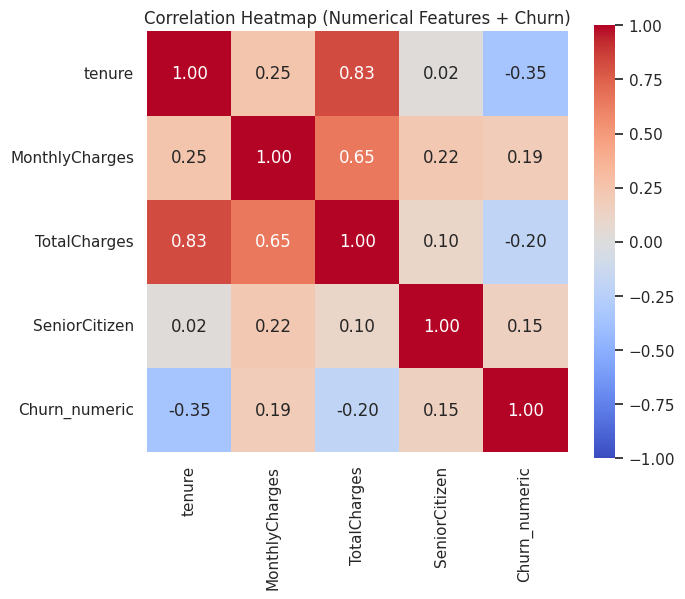

In [43]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation Heatmap (Numerical Features + Churn)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=150)
plt.show()


In [44]:
print("Correlation of each numerical feature with Churn (numeric-encoded):")
churn_corr = corr_matrix["Churn_numeric"].drop("Churn_numeric").sort_values(key=abs, ascending=False)
churn_corr


Correlation of each numerical feature with Churn (numeric-encoded):


tenure           -0.352229
TotalCharges     -0.199484
MonthlyCharges    0.193356
SeniorCitizen     0.150889
Name: Churn_numeric, dtype: float64

## 12. Key EDA Findings

*(This section is completed after running all cells above — see the executed notebook output for
the exact figures. A written summary with the real, computed numbers is also provided in the chat
response outside this notebook.)*

The findings below reference the outputs actually produced by the cells above in this notebook run:

- **Class imbalance:** the exact `Yes`/`No` counts and percentages are shown in Section 6. This
  dataset's minority class is `Churn = Yes`.
- **Data quality:** the exact count of blank `TotalCharges` values, and whether those rows share a
  common `tenure` value, is shown in Section 5.
- **Contract type pattern:** see the churn-rate-by-contract table/plot in Section 9 for the actual
  observed rates per contract type.
- **Internet service pattern:** see the churn-rate-by-internet-service table/plot in Section 9.
- **Payment method pattern:** see the churn-rate-by-payment-method table/plot in Section 9.
- **Tenure pattern:** see the churn-rate-by-tenure-group table/plot, and the tenure boxplot/violin
  plot vs. Churn in Sections 9-10, for the actual observed relationship.
- **Charges pattern:** see the churn-rate-by-monthly-charges-group table, and the
  MonthlyCharges/TotalCharges boxplots vs. Churn, in Sections 9-10.
- **Correlation:** see the correlation heatmap and the sorted correlation-with-Churn table in
  Section 11 for the actual linear associations found (remember: correlation, not causation).

All statements above are grounded in the specific numbers produced by this notebook run — refer to
the executed cell outputs for the precise values rather than treating this summary as a substitute
for them.

## 13. Data Preprocessing Recommendations (for Notebook 2)

Based on the data quality checks and patterns explored above, the next notebook
(`02_data_preprocessing.ipynb`) should:

1. **Handle `TotalCharges`:**
   - Convert from text to numeric (`pd.to_numeric(..., errors="coerce")`).
   - Investigate and handle the resulting missing values (Section 5 showed these correspond to
     `tenure == 0`, i.e., brand-new customers with no billing history yet). A sensible approach is
     to impute them as `0` (or `MonthlyCharges * tenure`, which is also `0` here) rather than
     dropping the rows, since dropping loses real customers from the dataset.

2. **Remove `customerID`:**
   - It is a unique identifier with no predictive value and must be dropped before modeling to
     avoid the model treating it as a feature.

3. **Categorical encoding:**
   - Binary Yes/No columns (`Partner`, `Dependents`, `PaperlessBilling`, `PhoneService`, `Churn`,
     etc.) can be label/binary encoded.
   - Multi-category nominal columns (`Contract`, `InternetService`, `PaymentMethod`,
     `MultipleLines`, and the "No internet service" style columns) should be one-hot encoded.
   - Encoding must be **fit only on the training data** (via a scikit-learn `Pipeline` /
     `ColumnTransformer`) and then applied to the test data, to avoid data leakage.

4. **Numerical scaling:**
   - `tenure`, `MonthlyCharges`, and `TotalCharges` should be scaled (e.g., `StandardScaler`) for
     the Logistic Regression model in particular. Scaling must be **fit only on the training set**.

5. **Feature engineering (candidates, to be finalized in Notebook 2):**
   - A `tenure_group` bucket, similar to the one used for EDA in this notebook.
   - A count of total subscribed services per customer.
   - Flags such as "has any streaming service" or "has any add-on security/support service."

6. **Train/test split:**
   - Perform a **stratified** train/test split on `Churn` (e.g., 80/20) so that the class
     proportion (~ the ratio observed in Section 6) is preserved in both sets. Use a fixed
     `random_state` for reproducibility.

7. **Class imbalance (SMOTE):**
   - Given the class imbalance confirmed in Section 6, apply **SMOTE only to the training data**,
     and only *after* the train/test split — never to the test set, and never before splitting.
   - SMOTE should be applied inside an `imblearn.pipeline.Pipeline` so that, during cross-validation,
     it is correctly re-applied within each fold rather than once globally (which would leak
     information across folds).

8. **Preventing data leakage — summary of rules to follow:**
   - Split the data into train/test **before** fitting any transformer (imputer, encoder, scaler).
   - Fit every transformer **only** on the training fold/set; only `.transform()` (never `.fit()`)
     on the test set.
   - Apply SMOTE **only** to the training data, after the split.
   - Do not use any information derived from the test set (e.g., its mean/std, its class balance)
     anywhere in the training process.
   - Wrap the entire preprocessing + resampling + model sequence in a single pipeline object so
     these rules are enforced automatically and consistently.
